## Import libraries and Preprocess Data ##

In [2]:
library(readxl)
library(readr)
library(ggplot2)
library(tidyr)
library(vegan)
library(tibble)
library(dplyr)
library(ggrepel)
library(grid)
library(patchwork)
library(scales)
library(stringr)
library(limma)
library(imputeLCMD)

## Change path ##

In [3]:
data_path <- file.path("metadata", "")
fig_path <- "."

## Fig 3.b ##

Permutation test for adonis under reduced model
Permutation: free
Number of permutations: 9999

adonis2(formula = bray_curtis_dist ~ group_for_permanova, permutations = 9999)
         Df SumOfSqs      R2      F Pr(>F)  
Model     1  0.17132 0.06162 2.5608 0.0474 *
Residual 39  2.60915 0.93838                
Total    40  2.78047 1.00000                
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


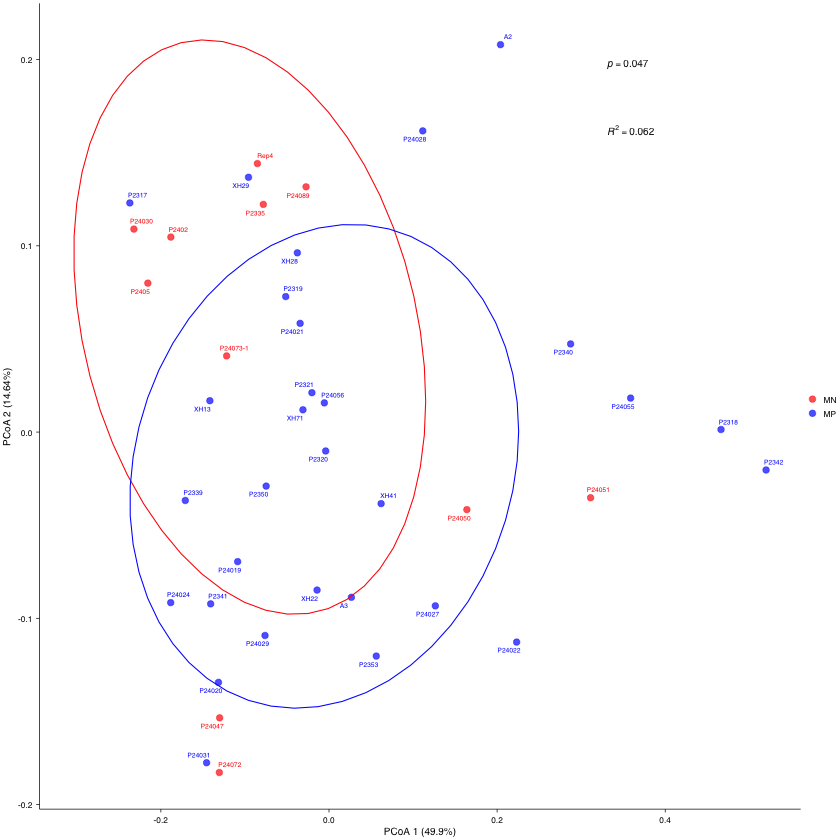

In [4]:
abundance_df <- read_excel(paste0(data_path,"genus_abundance.xlsx"))   #relative genus abundance
colnames(abundance_df)[1] <- "Genus"

group_info <- read_excel(paste0(data_path,"group_info.xlsx"), sheet = "PERMANOVA") #grouping info is stored here

sample_names <- sub("LFQ intensity ", "", colnames(abundance_df))
colnames(abundance_df) <- sample_names

abundance_df <- as.data.frame(abundance_df)
rownames(abundance_df) <- abundance_df[, 1]
abundance_df <- abundance_df[, -1]
abundance_df[is.na(abundance_df)] <- 0

abundance_df_t <- t(abundance_df)
bray_curtis_dist <- vegdist(abundance_df_t, method = "bray")

matching_data <- group_info[group_info$LabNo %in% sample_names, ]

pcoa_result <- cmdscale(bray_curtis_dist, k = 4, eig = TRUE)

pcoa_df <- as.data.frame(pcoa_result$points)
eig <- pcoa_result$eig
colnames(pcoa_df) <- c("PC1", "PC2", "PC3", "PC4")

pcoa_df$PC1 <- -pcoa_df$PC1
pcoa_df$PC2 <- -pcoa_df$PC2

pcoa_df$sample_id <- rownames(pcoa_df)
pcoa_df$milk_group <- matching_data$milk[match(rownames(pcoa_df), matching_data$LabNo)]
pcoa_df$milk_group <- recode(pcoa_df$milk_group, "no" = "MN", "yes" = "MP")

# PERMANOVA 
sample_names <- rownames(pcoa_df)
group_for_permanova <- pcoa_df$milk_group[match(sample_names, pcoa_df$sample_id)]

set.seed(42)
permanova_result <- adonis2(
  bray_curtis_dist ~ group_for_permanova,
  permutations = 9999
)
print(permanova_result)

r2_value <- permanova_result$R2[1]
p_value  <- permanova_result$`Pr(>F)`[1]

p_label_only <- if (p_value < 0.001) {
  "italic(p) < 0.001"
} else {
  paste0("italic(p) == ", formatC(p_value, format = "f", digits = 3))
}

r2_label_only <- paste0("italic(R)^2 == ", formatC(r2_value, format = "f", digits = 3))

fig_width <- 75
fig_height <- 70
font_family <- "Helvetica"
sample_font <- 5
axis_font <- 5
title_font <- 6
stat_font <- 6
point_size <- 1.7

x_range <- range(pcoa_df$PC1, na.rm = TRUE)
y_range <- range(pcoa_df$PC2, na.rm = TRUE)
x_pos <- x_range[2] - diff(x_range) * 0.25
y_pos_line1 <- y_range[2] - diff(y_range) * 0.02
y_pos_line2 <- y_range[2] - diff(y_range) * 0.11

p_pcoa <- ggplot(pcoa_df, aes(x = PC1, y = PC2, color = milk_group)) +
  geom_point(size = point_size, alpha = 0.7) +
  geom_text_repel(
    aes(label = sample_id), family = "Helvetica", fontface = "plain",
    size = 4 / .pt, box.padding = 0.15, point.padding = 0.1,
    segment.color = "grey50", segment.size = 0.15,
    show.legend = FALSE, max.overlaps = Inf, seed = 42
  ) + 
  stat_ellipse(level = 0.68, linewidth = 0.3, show.legend = FALSE) +
  scale_color_manual(values = c("MN" = "red", "MP" = "blue"), breaks = c("MN", "MP")) +
  annotate("text", x = x_pos, y = y_pos_line1, label = p_label_only,
           hjust = 0, vjust = 1, family = font_family, size = stat_font / .pt, parse = TRUE, color = "black") +
  annotate("text", x = x_pos, y = y_pos_line2, label = r2_label_only,
           hjust = 0, vjust = 1, family = font_family, size = stat_font / .pt, parse = TRUE, color = "black") +
  labs(x = paste0("PCoA 1 (", format(100 * eig[1] / sum(eig), digits = 4), "%)"),
       y = paste0("PCoA 2 (", format(100 * eig[2] / sum(eig), digits = 4), "%)")) +
  theme_minimal(base_size = axis_font, base_family = font_family) +
  theme(
    text = element_text(family = font_family),
    panel.grid = element_blank(), panel.background = element_blank(),
    axis.line = element_line(linewidth = 0.2, color = "black"),
    axis.ticks = element_line(linewidth = 0.2, color = "black"),
    axis.ticks.length = grid::unit(0.7, "mm"),
    axis.title = element_text(size = title_font),
    axis.title.x = element_text(margin = margin(t = 2)),
    axis.title.y = element_text(margin = margin(r = 2)),
    axis.text = element_text(size = axis_font, color = "black"),
    legend.title = element_blank(), legend.text = element_text(size = 5),
    legend.key.size = grid::unit(3, "mm"), legend.spacing.y = grid::unit(0, "mm"),
    legend.margin = margin(0, 0, 0, 0), legend.box.spacing = grid::unit(1, "mm"),
    plot.margin = margin(2, 2, 2, 2)
  )

dir.create(fig_path, recursive = TRUE, showWarnings = FALSE)
#ggsave(file.path(fig_path, "pcoa.pdf"), plot = p_pcoa, device = cairo_pdf,
       #width = fig_width, height = fig_height, units = "mm", family = font_family, bg = "white")

p_pcoa

## Fig 3.c ##


MN MP 
11 30 


	Wilcoxon rank sum exact test

data:  shannon_index by milk_group
W = 122, p-value = 0.2145
alternative hypothesis: true location shift is not equal to 0



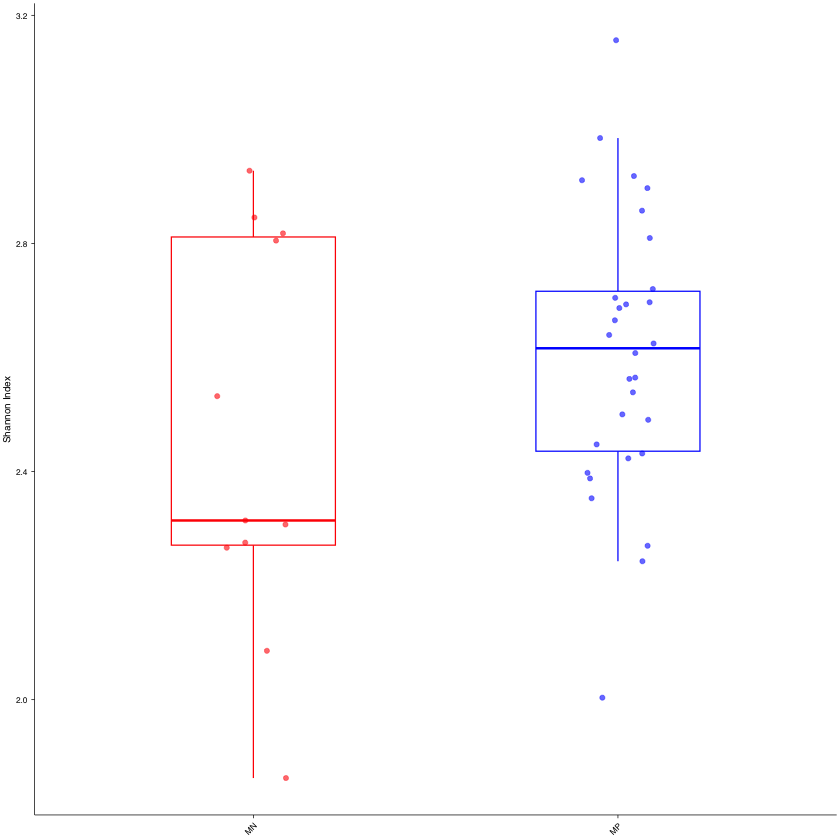

In [6]:
fig_width <- 34
fig_height <- 65
font_family <- "Helvetica"

shannon_index <- vegan::diversity(abundance_df_t, index = "shannon")
pcoa_df$shannon_index <- shannon_index[match(pcoa_df$sample_id, names(shannon_index))]
pcoa_df$milk_group <- factor(pcoa_df$milk_group, levels = c("MN", "MP"))
table(pcoa_df$milk_group)

group_n <- table(pcoa_df$milk_group)

p_shannon <- ggplot(pcoa_df, aes(x = milk_group, y = shannon_index)) +
  geom_boxplot(aes(color = milk_group), outlier.shape = NA, linewidth = 0.35,
               width = 0.45, fill = "white") +
  geom_point(aes(color = milk_group), position = position_jitter(width = 0.1, height = 0, seed = 42),
             size = 1.3, alpha = 0.6) +
  scale_color_manual(values = c("MN" = "red", "MP" = "blue")) +
  labs(x = NULL, y = "Shannon Index") +
  theme_minimal(base_size = 5, base_family = font_family) +
  theme(
    panel.grid = element_blank(), panel.background = element_blank(),
    axis.line = element_line(linewidth = 0.2, color = "black"),
    axis.ticks = element_line(linewidth = 0.2, color = "black"),
    axis.ticks.length = grid::unit(0.7, "mm"),
    axis.title.y = element_text(size = 6, margin = margin(r = 2)),
    axis.text = element_text(size = 5, color = "black"),
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none", plot.margin = margin(2, 2, 2, 2)
  )

wilcox_result <- wilcox.test(shannon_index ~ milk_group, data = pcoa_df)
print(wilcox_result)

dir.create(fig_path, recursive = TRUE, showWarnings = FALSE)
#ggsave(file.path(fig_path, "alpha_diversity.pdf"), plot = p_shannon, device = cairo_pdf,
       #width = fig_width, height = fig_height, units = "mm", family = font_family, bg = "white")

print(p_shannon)

## ED Fig. 4b ##

Rows: 44 Columns: 2
-- Column specification --------------------------------------------------------
Delimiter: ","
chr (2): Genus, Color

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.


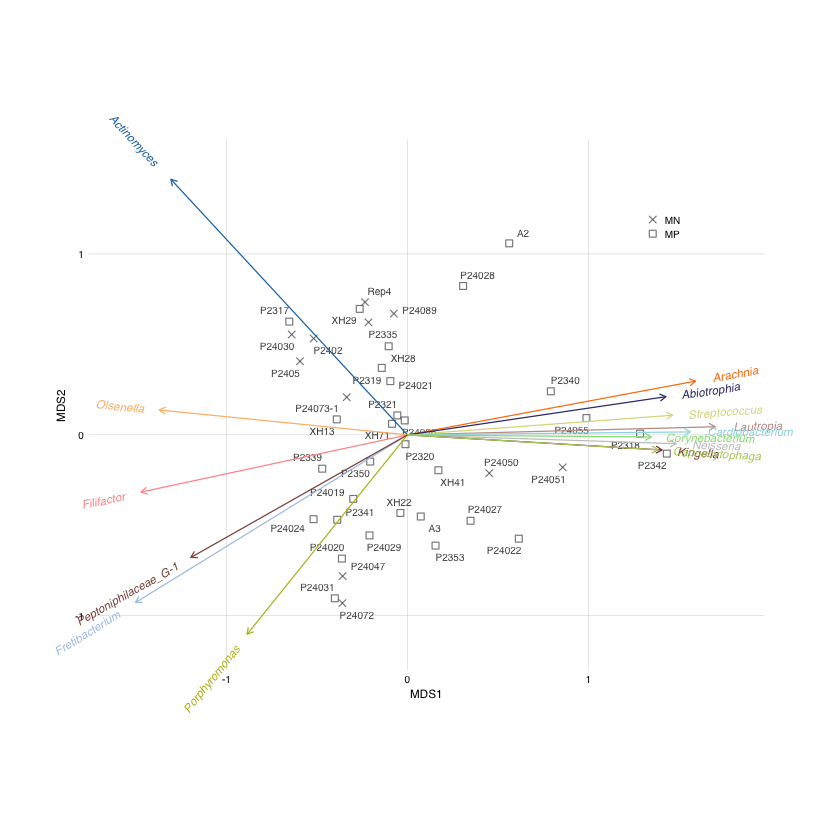

In [7]:
color_map <- read_csv(paste0(data_path, "genus_color_mapping.csv"))
genus_colors <- setNames(color_map$Color, color_map$Genus)

bray_curtis_dist <- vegdist(abundance_df_t, method = "bray")
pcoa <- capscale(bray_curtis_dist ~ 1)
fit <- envfit(pcoa, abundance_df_t, perm = 19999)

eig <- pcoa$CA$eig

sample_scores <- as.data.frame(vegan::scores(pcoa, display = "sites"))
sample_scores$Sample <- rownames(sample_scores)
sample_scores$MDS1 <- -sample_scores$MDS1
#sample_scores$MDS2 <- -sample_scores$MDS2

matching_data <- group_info[group_info$LabNo %in% sample_scores$Sample, ]
sample_scores$milk_group <- matching_data$milk[match(sample_scores$Sample, matching_data$LabNo)]
sample_scores$milk_group <- recode(sample_scores$milk_group, "no" = "MN", "yes" = "MP")

vec_scores <- as.data.frame(vegan::scores(fit, display = "vectors"))

vec_scores$Taxon <- rownames(vec_scores)
vec_scores$pval <- fit$vectors$pvals
vec_scores$r <- fit$vectors$r
vec_scores$MDS1 <- -vec_scores$MDS1
#vec_scores$MDS2 <- -vec_scores$MDS2

# FDR correction
vec_scores_clean <- vec_scores[!grepl(";", vec_scores$Taxon), ]
vec_scores_clean$qval <- p.adjust(vec_scores_clean$pval, method = "fdr")

sig_taxa <- vec_scores_clean[vec_scores_clean$qval < 0.05, ]
sig_taxa <- sig_taxa[order(sig_taxa$r, decreasing = TRUE), ]
top_taxa <- head(sig_taxa, 15)

arrow_scale <- 2
push_factor <- 1.06

top_taxa <- top_taxa %>%
  mutate(
    x_end = MDS1 * arrow_scale,y_end = MDS2 * arrow_scale,
    label_x = x_end * push_factor,label_y = y_end * push_factor,
    raw_angle = atan2(y_end, x_end) * 180 / pi,
    angle = ifelse(x_end > 0, raw_angle, raw_angle + 180),
    hjust = ifelse(x_end > 0, 0, 1)
  )

font_family <- "Helvetica"
pt_to_linewidth <- function(pt) pt * 96 / (72 * ggplot2::.pt)
arrow_lw <- pt_to_linewidth(0.75)
grid_lw <- pt_to_linewidth(0.25)

p <- ggplot(sample_scores, aes(x = MDS1, y = MDS2)) +
  geom_point(
    aes(shape = milk_group), color = "grey30", size = 1.6, stroke = 0.5, alpha = 0.7
  ) +
  scale_shape_manual(values = c("MN" = 4, "MP" = 0), name = "") +
  geom_text_repel(
    aes(label = Sample),family = font_family,color = "grey30",size = 6 / ggplot2::.pt,
    max.overlaps = Inf,box.padding = 0.25,point.padding = 0.20,
    force = 0.4,force_pull = 2,segment.color = "grey70",
    segment.size = 0.4,show.legend = FALSE
  ) +
  geom_segment(
    data = top_taxa,
    aes(x = 0, y = 0, xend = x_end, yend = y_end, color = Taxon),
    arrow = arrow(length = grid::unit(1.5, "mm")),
    linewidth = arrow_lw
  ) +
  geom_text(
    data = top_taxa,
    aes(
      x = label_x, y = label_y, label = Taxon,
      color = Taxon, angle = angle, hjust = hjust
    ),
    family = font_family,size = 7 / ggplot2::.pt,
    fontface = "italic",vjust = 0.5
  ) +
  scale_color_manual(values = genus_colors, guide = "none") +
  theme_minimal(base_size = 6, base_family = font_family) +
  coord_fixed(clip = "off") +
  theme(
    text = element_text(family = font_family, color = "black"),
    axis.title = element_text(size = 7),
    axis.title.x = element_text(margin = margin(t = 3, unit = "pt")),
    axis.title.y = element_text(margin = margin(r = 3, unit = "pt")),
    axis.text = element_text(size = 6, color = "black"),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(color = "grey80", linewidth = grid_lw),
    panel.background = element_blank(),
    legend.position = c(0.85, 0.85),
    legend.title = element_text(size = 6, face = "bold"),
    legend.text = element_text(size = 6),
    legend.key.size = grid::unit(3, "mm"),
    plot.background = element_rect(fill = "white", color = NA),
    plot.margin = margin(4, 16, 4, 12, "mm")
  )


#ggsave(
  #filename = file.path(fig_path, "pcoa_envfit.pdf"),
  #plot = p, device = grDevices::pdf,
  #family = font_family, useDingbats = FALSE,
  #width = 180, height = 105, units = "mm", bg = "white"
#)

print(p)


## ED Fig. 5a, b ##

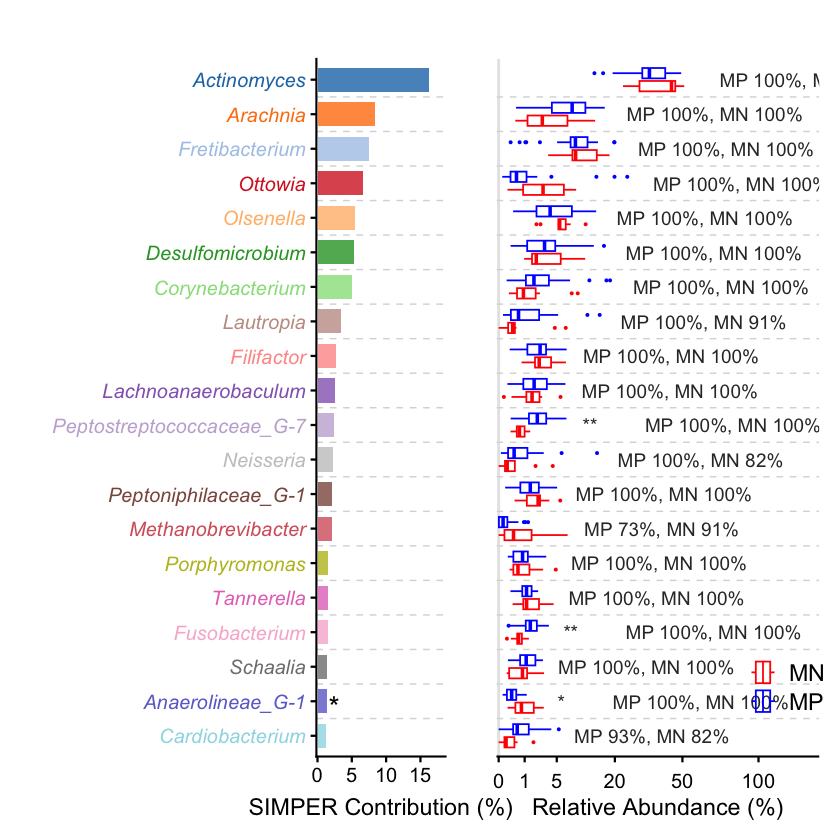

In [8]:
abundance_df_t <- t(abundance_df)
milk_group <- pcoa_df$milk_group

if (!identical(rownames(abundance_df_t), rownames(pcoa_df))) {
  stop("sample matching error")
}

#SIMPER
set.seed(123) 
sim_res <- simper(abundance_df_t, group = milk_group, permutations = 19999)

sim_summary <- summary(sim_res)
comp_name <- names(sim_summary)[1]
sim_data <- as.data.frame(sim_summary[[comp_name]])
sim_data$Genus <- rownames(sim_data)

sim_data <- sim_data %>%
  mutate(Contribution_Pct = (average / sum(average)) * 100) %>%
  arrange(desc(Contribution_Pct))

mp_samples <- pcoa_df$sample_id[pcoa_df$milk_group == "MP"]
mn_samples <- pcoa_df$sample_id[pcoa_df$milk_group == "MN"]

# Genus prevalence
abund_matrix <- as.matrix(abundance_df)

sim_data$Prev_MP <- NA
sim_data$Prev_MN <- NA

for (i in 1:nrow(sim_data)) {
  g <- sim_data$Genus[i]

  if (g %in% rownames(abund_matrix)) {
    vals_mp <- as.numeric(abund_matrix[g, mp_samples])
    vals_mn <- as.numeric(abund_matrix[g, mn_samples])

    sim_data$Prev_MP[i] <- (sum(vals_mp > 0, na.rm = TRUE) / length(vals_mp)) * 100
    sim_data$Prev_MN[i] <- (sum(vals_mn > 0, na.rm = TRUE) / length(vals_mn)) * 100

    mw_test <- tryCatch(
      wilcox.test(vals_mp, vals_mn, exact = FALSE),
      error = function(e) NULL
    )
    sim_data$MW_P[i] <- if (!is.null(mw_test)) mw_test$p.value else NA
  }
}

# use only distinct genus for SIMPER permutation tests fdr correction
unique_sim_data <- sim_data[!grepl(";", rownames(sim_data)), ]

unique_sim_data$q_value_simper <- p.adjust(unique_sim_data$p, method = "fdr")

unique_sim_data <- unique_sim_data %>% arrange(desc(Contribution_Pct))
top_drivers <- head(unique_sim_data, 20)

# use only top 20 drivers for genus abundance U tests fdr correction
top_drivers$q_value_top20 <- p.adjust(top_drivers$MW_P, method = "fdr")
top_drivers$Genus <- factor(top_drivers$Genus, levels = rev(top_drivers$Genus))

target_taxa <- as.character(top_drivers$Genus)

abund_subset <- as.data.frame(abundance_df[target_taxa, ])
abund_subset$Genus <- rownames(abund_subset)

abund_long <- abund_subset %>%
  pivot_longer(cols = -Genus, names_to = "Sample", values_to = "Abundance") %>%
  mutate(
    Abundance = as.numeric(Abundance) * 100, 
    Group = pcoa_df$milk_group[match(Sample, pcoa_df$sample_id)]
  )

abund_long$Genus <- factor(abund_long$Genus, levels = levels(top_drivers$Genus))
hline_positions <- seq(1.5, length(levels(top_drivers$Genus)) - 0.5, by = 1)
y_axis_colors <- genus_colors[levels(top_drivers$Genus)]

top_drivers <- top_drivers %>%
  mutate(
    Star_Label = case_when(
      q_value_top20 < 0.01 ~ "**",
      q_value_top20 < 0.05 ~ "*",
      TRUE ~ ""
    ),
    Prev_Label = paste0("MP ", round(Prev_MP, 0), "%, MN ", round(Prev_MN, 0), "%"),
    
    Final_Label = ifelse(Star_Label == "", Prev_Label, paste0(Star_Label, "         ", Prev_Label))
  )

max_abundances <- abund_long %>%
  group_by(Genus) %>%
  summarize(Max_Abund = max(Abundance, na.rm = TRUE))

top_drivers$Text_X_Pos <- max_abundances$Max_Abund[match(top_drivers$Genus, max_abundances$Genus)] * 1.4 + 1


p_left <- ggplot(top_drivers, aes(x = Contribution_Pct, y = Genus, fill = Genus)) +
  geom_hline(yintercept = hline_positions, color = "grey85", linetype = "dashed", linewidth = 0.4) +
  geom_bar(stat = "identity", color = NA, alpha = 0.8, width = 0.7) +
  geom_text(
    aes(label = ifelse(q_value_simper < 0.01, "**", 
                      ifelse(q_value_simper < 0.05, "*", ""))),  # FDR-adjusted SIMPER p-values
    x = top_drivers$Contribution_Pct + 0.3, 
    color = "black", 
    size = 6, 
    vjust = 0.75, 
    hjust = 0
  ) +
  scale_x_continuous(expand = expansion(mult = c(0.01, 0.15))) + 
  scale_fill_manual(values = genus_colors) +
  labs(title = "", x = "SIMPER Contribution (%)", y = "") +
  theme_classic(base_size = 14) +
  theme(
    axis.text.y = element_text(color = y_axis_colors, size = 12, face = "italic"), 
    axis.line.y = element_line(linewidth = 0.6, color = "black"), 
    axis.ticks.y = element_line(color = "black"),
    axis.title.x = element_text(size = 14),
    axis.text.x = element_text(color = "black", size = 12),
    axis.line.x = element_line(linewidth = 0.6, color = "black"), 
    axis.ticks.x = element_line(color = "black"),
    legend.position = "none"
  )

p_right <- ggplot(abund_long, aes(x = Abundance, y = Genus, fill = Group)) +
  geom_vline(xintercept = 0, color = "gray90", linetype = "solid", linewidth = 0.8) +
  geom_hline(yintercept = hline_positions, color = "grey85", linetype = "dashed", linewidth = 0.4) +
  
  geom_boxplot(
    position = position_dodge(width = 0.75), outlier.size = 0.8, outlier.shape = 16,
    aes(color = Group), linewidth = 0.5, width = 0.6, fill = NA
  ) +
  
  geom_text(
    data = top_drivers,
    aes(x = Text_X_Pos, y = Genus,label = Final_Label),
    inherit.aes = FALSE, color = "grey20",size = 4, vjust = 0.5,hjust = 0
  ) +
  scale_color_manual(values = c("MP" = "blue", "MN" = "red")) +
  
  scale_x_continuous(trans = "sqrt", breaks = c(0, 1, 5, 20, 50, 100), 
    limits = c(0, NA), expand = expansion(mult = c(0.01, 0.45)) 
  ) +
  labs(title = "", x = "Relative Abundance (%)", y = "") +
  theme_minimal(base_size = 14) +
  theme(
    panel.grid.major = element_blank(),  
    panel.grid.minor = element_blank(),  
    panel.background = element_blank(),  
    axis.line.y = element_blank(),
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank(),
    axis.title.x = element_text(size = 14),
    axis.text.x = element_text(color = "black", size = 12),
    axis.line.x = element_line(linewidth = 0.6, color = "black"),
    axis.ticks.x = element_line(color = "black"),
    legend.position = c(0.9, 0.1), 
    legend.title = element_blank(),
    legend.text = element_text(size = 14) 
  )

combined_plot <- p_left + p_right + plot_layout(widths = c(0.8, 2))
print(combined_plot)
#ggsave(filename = file.path(fig_path,"SIMPER.pdf"), combined_plot, width = 12, height = 7)

## ED Fig. 5c, d ##

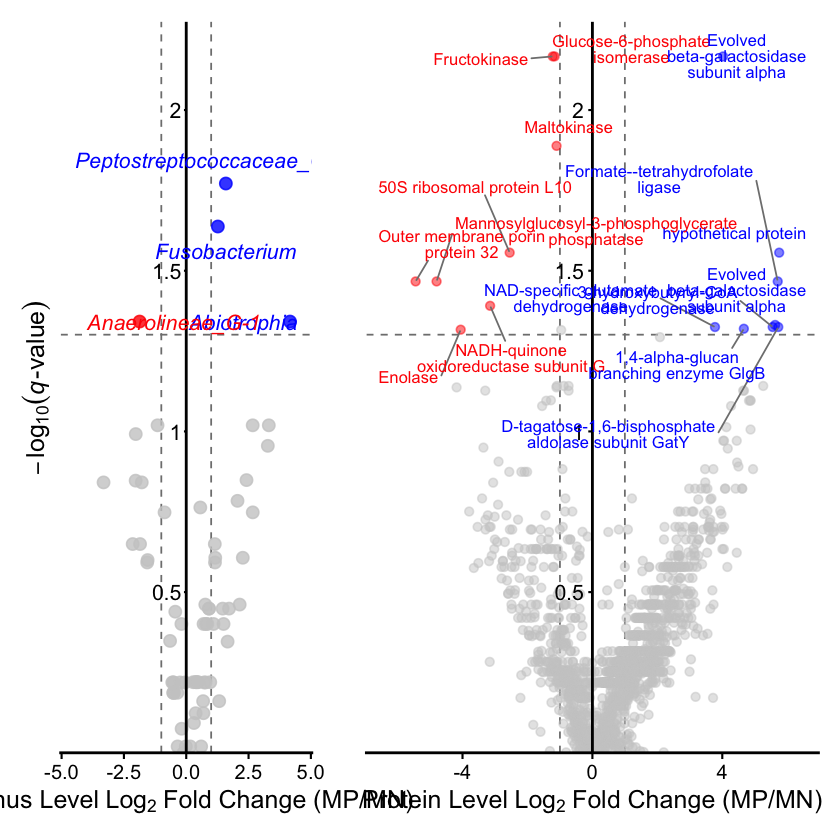

In [9]:
file_prot <- paste0(data_path,"protein_groups_filtered.xlsx") # relative protein abundance
protein_groups <- read_excel(file_prot)

lfq_cols <- grep("^LFQ intensity ", colnames(protein_groups), value = TRUE)
prot_df <- as.data.frame(protein_groups[, lfq_cols])
colnames(prot_df) <- sub("^LFQ intensity ", "", colnames(prot_df))
prot_df[is.na(prot_df)] <- 0

# use id as labels for protein groups
rownames(prot_df) <- protein_groups$id

# keep only distinct genus for fdr correction and volcano plot, otherwise the penalty would be too stringent 
unique_abundance_df <- abundance_df[!grepl(";", rownames(abundance_df)), ]

samples <- colnames(unique_abundance_df)
matching_data <- group_info[match(samples, group_info$LabNo), ]
group_labels <- matching_data$milk

samples_prot <- colnames(prot_df)
matching_data_prot <- group_info[match(samples_prot, group_info$LabNo), ]
group_labels_prot <- matching_data_prot$milk

# calculate log2FC
calculate_stats <- function(matrix, groups) {

  all_vals <- as.numeric(as.matrix(matrix))
  nonzero_vals <- all_vals[all_vals > 0]
  pseudo <- min(nonzero_vals) / 2
  
  df_res <- data.frame(
    Feature = rownames(matrix),
    Log2FC = numeric(nrow(matrix)),
    P_value = numeric(nrow(matrix)),
    stringsAsFactors = FALSE
  )
  
  for (i in 1:nrow(matrix)) {
    vals <- as.numeric(matrix[i, ])
    
    mp_vals <- vals[groups == "yes"]
    mn_vals <- vals[groups == "no"]
    
    mp_log <- log2(mp_vals + pseudo)
    mn_log <- log2(mn_vals + pseudo)
    df_res$Log2FC[i] <- mean(mp_log) - mean(mn_log)
    
    test_res <- wilcox.test(mp_vals, mn_vals, exact = FALSE)
    df_res$P_value[i] <- test_res$p.value
  }
  
  df_res$FDR <- p.adjust(df_res$P_value, method = "BH")
  df_res$neg_log10_FDR <- -log10(df_res$FDR)
  
  return(df_res)
}

res_genus <- calculate_stats(unique_abundance_df, group_labels)
res_prot <- calculate_stats(prot_df, group_labels_prot)

fdr_threshold <- 0.05
fc_threshold <- 1

res_genus$Significance <- "Not Significant"
res_genus$Significance[res_genus$FDR < fdr_threshold & res_genus$Log2FC > fc_threshold] <- "MP"
res_genus$Significance[res_genus$FDR < fdr_threshold & res_genus$Log2FC < -fc_threshold] <- "MN"
res_genus$Label <- ifelse(res_genus$Significance != "Not Significant", res_genus$Feature, "")

res_prot$Significance <- "Not Significant"
res_prot$Significance[res_prot$FDR < fdr_threshold & res_prot$Log2FC > fc_threshold] <- "MP"
res_prot$Significance[res_prot$FDR < fdr_threshold & res_prot$Log2FC < -fc_threshold] <- "MN"

res_prot$Label <- ""

id_to_name_map <- setNames(
  as.character(protein_groups$`Unique Major Protein Names`),
  as.character(protein_groups$id)
)

res_prot$Protein_Name <- id_to_name_map[as.character(res_prot$Feature)]

sig_prots <- res_prot %>% filter(Significance != "Not Significant" & !grepl(";", Protein_Name))

res_prot$Label[res_prot$Feature %in% sig_prots$Feature] <- str_wrap(
  res_prot$Protein_Name[res_prot$Feature %in% sig_prots$Feature], width = 25
)

color_mapping <- c("MP" = "blue", "MN" = "red", "Not Significant" = "grey80")

max_x_genus <- max(abs(res_genus$Log2FC), na.rm = TRUE) * 1.1
tick_g <- max_x_genus * 0.02
off_g  <- max_x_genus * 0.04

max_x_prot <- max(abs(res_prot$Log2FC), na.rm = TRUE) * 1.1
tick_p <- max_x_prot * 0.02
off_p  <- max_x_prot * 0.04

max_y_genus <- max(res_genus$neg_log10_FDR, na.rm = TRUE) * 1.05
max_y_prot <- max(res_prot$neg_log10_FDR, na.rm = TRUE) * 1.05
global_max_y <- max(c(max_y_genus, max_y_prot), na.rm = TRUE)

global_y_breaks <- pretty(c(0, global_max_y))
global_y_breaks <- global_y_breaks[global_y_breaks > 0 & global_y_breaks <= global_max_y]


p_genus <- ggplot(res_genus, aes(x = Log2FC, y = neg_log10_FDR, color = Significance)) +
  geom_hline(yintercept = -log10(fdr_threshold), linetype = "dashed", 
    color = "grey50", linewidth = 0.5
  ) +
  geom_vline(xintercept = c(-fc_threshold, fc_threshold), linetype = "dashed", 
    color = "grey50", linewidth = 0.5
  ) +
  geom_point(alpha = 0.8, size = 3) +
  scale_color_manual(values = color_mapping) +
  annotate("segment", x = 0, xend = 0, y = 0, yend = global_max_y, 
    color = "black", linewidth = 0.8
  ) +
  annotate("segment", x = 0, xend = -tick_g, y = global_y_breaks, 
    yend = global_y_breaks, color = "black", linewidth = 0.6
  ) +
  annotate("text", x = -off_g, y = global_y_breaks, label = global_y_breaks, 
    hjust = 1, size = 4.5, color = "black"
  ) +
  geom_text_repel(aes(label = Label), size = 4.5, fontface = "italic", 
                  box.padding = 0.6, max.overlaps = Inf, show.legend = FALSE, lineheight = 0.8) +
  scale_x_continuous(limits = c(-max_x_genus, max_x_genus)) +
  scale_y_continuous(limits = c(0, global_max_y), expand = c(0, 0)) +
  labs(title = NULL, 
       x = expression("Genus Level"~Log[2]~"Fold Change (MP/MN)"), 
       y = expression(-log[10](italic(q)*"-value"))) +
  theme_classic(base_size = 15) +
  theme(
    legend.position = "none", 
    axis.line.x = element_line(color = "black", linewidth = 0.8),
    axis.ticks.x = element_line(color = "black", linewidth = 0.6),
    axis.text.x = element_text(color = "black", size = 12),
    axis.line.y = element_blank(),
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank()
  )

p_prot <- ggplot(res_prot, aes(x = Log2FC, y = neg_log10_FDR, color = Significance)) +
  geom_hline(yintercept = -log10(fdr_threshold), linetype = "dashed", 
    color = "grey50", linewidth = 0.5
  ) +
  geom_vline(xintercept = c(-fc_threshold, fc_threshold), linetype = "dashed", 
    color = "grey50", linewidth = 0.5
  ) +
  geom_point(alpha = 0.5, size = 2) + 
  scale_color_manual(values = color_mapping) +
  annotate("segment", x = 0, xend = 0, y = 0, yend = global_max_y, 
    color = "black", linewidth = 0.8
  ) +
  annotate("segment", x = 0, xend = -tick_p, y = global_y_breaks, 
    yend = global_y_breaks, color = "black", linewidth = 0.6
  ) +
  annotate("text", x = -off_p, y = global_y_breaks, label = global_y_breaks, 
    hjust = 1, size = 4.5, color = "black"
  ) +
  geom_text_repel(aes(label = Label), size = 3.5, fontface = "plain", 
                  box.padding = 0.5, max.overlaps = Inf, show.legend = FALSE, 
                  segment.color = "grey50", lineheight = 0.8) +
  scale_x_continuous(limits = c(-max_x_prot, max_x_prot)) +
  scale_y_continuous(limits = c(0, global_max_y), expand = c(0, 0)) +
  labs(title = NULL, x = expression("Protein Level"~Log[2]~"Fold Change (MP/MN)"), y = "") +
  theme_classic(base_size = 15) +
  theme(
    legend.position = "right", 
    legend.title = element_blank(), 
    axis.line.x = element_line(color = "black", linewidth = 0.8),
    axis.ticks.x = element_line(color = "black", linewidth = 0.6),
    axis.text.x = element_text(color = "black", size = 12),
    axis.line.y = element_blank(),
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank()
  )

combined_plot <- p_genus + (p_prot + theme(legend.position = "none")) + plot_layout(widths = c(1, 1.8)) 

print(combined_plot)
#ggsave(filename = file.path(fig_path,"Volcano_mean.pdf"), combined_plot, width = 14, height = 5, dpi = 300)

## Fig. S9 limma ##

protein-level group filtering: 1878 -> 690 
genus-level group filtering: 68 -> 47 
[1] 0.9713078
[1] 1.227777


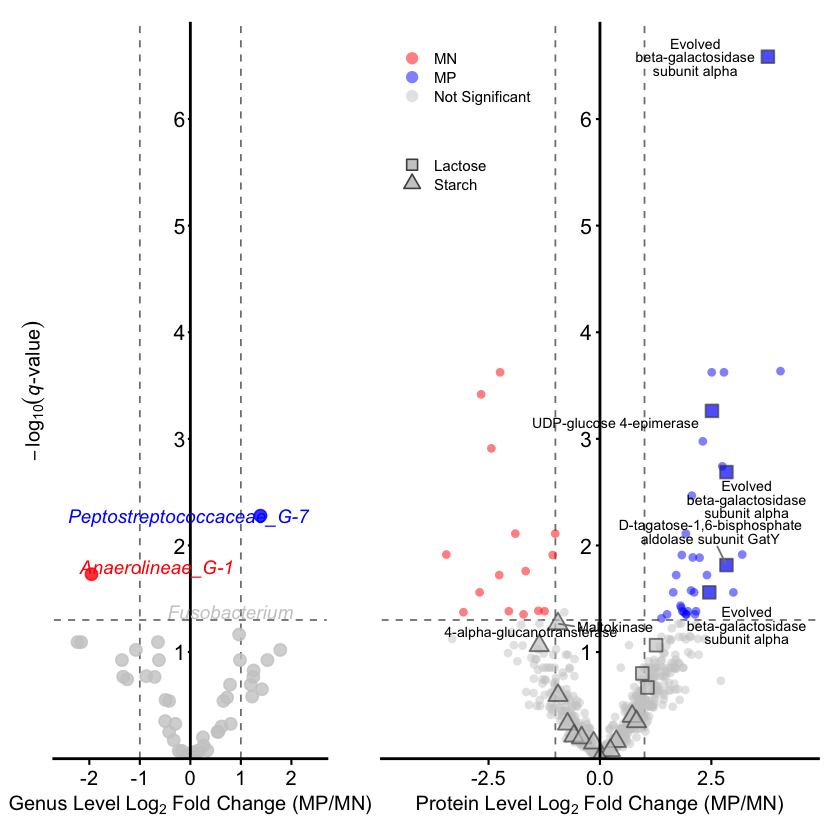

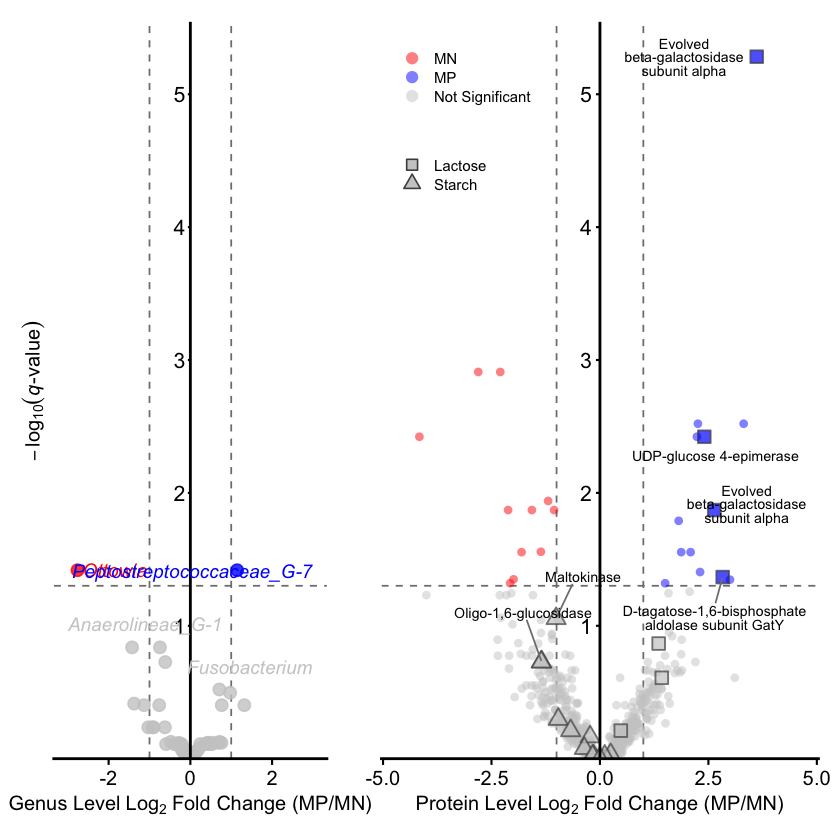

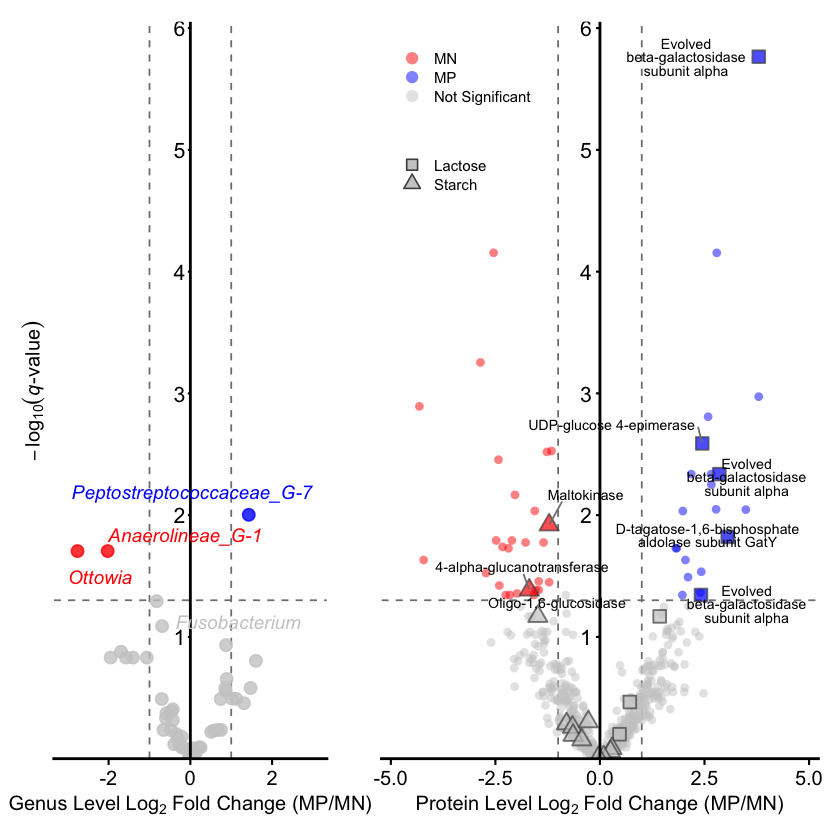

In [ ]:
file_path <- paste0(data_path, "proteingroups_annotated.txt") # raw LFQ intensities
protein_groups_ab <- read_delim(file_path, delim = "\t", col_types = cols(.default = "c"))

protein_groups_ab <- protein_groups_ab %>%
  filter(Reverse != "+" | is.na(Reverse)) %>%
  filter(`Only identified by site` != "+" | is.na(`Only identified by site`)) %>%
  filter(`Potential contaminant` != "+" | is.na(`Potential contaminant`))

protein_groups_ab <- protein_groups_ab %>%
  mutate(`Unique peptides` = as.numeric(`Unique peptides`),
         `Razor + unique peptides` = as.numeric(`Razor + unique peptides`),
         `Q-value` = as.numeric(`Q-value`))

protein_filtered_ab <- protein_groups_ab %>%
  filter(`Unique peptides` >= 1, `Razor + unique peptides` >= 2, `Q-value` <= 0.001)

lfq_cols_names <- grep("^LFQ intensity ", colnames(protein_filtered_ab), value = TRUE)
protein_filtered_ab <- protein_filtered_ab %>%
  filter(rowSums(across(all_of(lfq_cols_names), ~ as.numeric(.x) > 0), na.rm = TRUE) > 0)

# protein level
lfq_cols <- grep("^LFQ intensity ", colnames(protein_filtered_ab))
lfq_cols_names <- colnames(protein_filtered_ab)[lfq_cols]
protein_filtered_ab[, lfq_cols] <- lapply(protein_filtered_ab[, lfq_cols], as.numeric)

lfq_mat <- as.matrix(protein_filtered_ab[, lfq_cols])
rownames(lfq_mat) <- protein_filtered_ab$id
colnames(lfq_mat) <- sub("^LFQ intensity ", "", colnames(lfq_mat))
lfq_mat[lfq_mat == 0] <- NA

lfq_log2 <- log2(lfq_mat)

id_mapping <- protein_filtered_ab %>%
  select(id, `Unique Major Protein Names`, `Unique Major Genus`) %>%
  distinct()

# genus level (only distinct genera included)
genus_raw_df <- protein_filtered_ab %>%
  select(`Unique Major Genus`, all_of(lfq_cols_names)) %>%
  filter(!is.na(`Unique Major Genus`), `Unique Major Genus` != "", !grepl(";", `Unique Major Genus`))

genus_sum_df <- genus_raw_df %>%
  group_by(`Unique Major Genus`) %>%
  summarise(across(all_of(lfq_cols_names), ~ sum(.x, na.rm = TRUE))) %>%
  ungroup()

genus_mat <- as.matrix(genus_sum_df[, lfq_cols_names])
rownames(genus_mat) <- genus_sum_df$`Unique Major Genus`
colnames(genus_mat) <- sub("^LFQ intensity ", "", colnames(genus_mat))
genus_mat[genus_mat == 0] <- NA
genus_log2 <- log2(genus_mat)

group_info <- read_excel(paste0(data_path, "group_info.xlsx"), sheet = "PERMANOVA")
MP <- group_info$LabNo[group_info$milk == "yes"]
MN <- group_info$LabNo[group_info$milk == "no"]

build_group <- function(sample_names, MP, MN) {
  g <- rep(NA_character_, length(sample_names))
  g[sample_names %in% MP] <- "MP"
  g[sample_names %in% MN] <- "MN"
  factor(g, levels = c("MN", "MP"))
}

group_prot <- build_group(colnames(lfq_log2), MP, MN)
group_genus <- build_group(colnames(genus_log2), MP, MN)
names(group_prot) <- colnames(lfq_log2)
names(group_genus) <- colnames(genus_log2)

# retain genera/proteins detected in ≥ 50% of samples in at least one group
filter_by_group <- function(mat, group, min_rate = 0.5) {
  group <- group[colnames(mat)]
  keep <- apply(mat, 1, function(x) {
    mn_rate <- mean(!is.na(x[group == "MN"]))
    mp_rate <- mean(!is.na(x[group == "MP"]))
    mn_rate >= min_rate | mp_rate >= min_rate
  })
  mat[keep, , drop = FALSE]
}

lfq_log2_filtered <- filter_by_group(lfq_log2, group_prot)
genus_log2_filtered <- filter_by_group(genus_log2, group_genus)

cat("protein-level group filtering:", nrow(lfq_log2), "->", nrow(lfq_log2_filtered), "\n")
cat("genus-level group filtering:", nrow(genus_log2), "->", nrow(genus_log2_filtered), "\n")

# protein-level: no additional normalization (sample medians well-aligned)
# genus-level: loessf normalization
genus_log2_normalized <- normalizeCyclicLoess(genus_log2_filtered, method = "fast")

# MinProb imputation
set.seed(123)
lfq_imputed <- impute.MinProb(as.matrix(lfq_log2_filtered), q = 0.01, tune.sigma = 1)
genus_imputed <- impute.MinProb(as.matrix(genus_log2_normalized), q = 0.01, tune.sigma = 1)

# sample-level covariates
protein_detection_count <- colSums(!is.na(lfq_mat))
sample_total_lfq <- colSums(lfq_mat, na.rm = TRUE)

# Z-score transformation
scale_covariate <- function(x) {
  x_scaled <- as.numeric(scale(x))
  names(x_scaled) <- names(x)
  x_scaled
}

depth_prot_scaled <- scale_covariate(protein_detection_count[colnames(lfq_imputed)])
depth_genus_scaled <- scale_covariate(protein_detection_count[colnames(genus_imputed)])
totalLFQ_prot_scaled <- scale_covariate(sample_total_lfq[colnames(lfq_imputed)])
totalLFQ_genus_scaled <- scale_covariate(sample_total_lfq[colnames(genus_imputed)])

# limma
run_limma <- function(mat, group, covariate = NULL) {
  group <- droplevels(group[colnames(mat)])
  if (is.null(covariate)) {
    design <- model.matrix(~ 0 + group)
  } else {
    covariate <- covariate[colnames(mat)]
    design <- model.matrix(~ 0 + group + covariate)
  }
  colnames(design) <- c(levels(group), if (!is.null(covariate)) "Covariate")
  contrast <- makeContrasts(MP - MN, levels = design)
  fit <- lmFit(mat, design)
  fit2 <- eBayes(contrasts.fit(fit, contrast))
  topTable(fit2, number = Inf, adjust.method = "BH")
}

# unadjusted limma
results_prot <- run_limma(lfq_imputed, group_prot)
results_genus <- run_limma(genus_imputed, group_genus)

# limma adjusted for protein detection count
results_prot_depth <- run_limma(lfq_imputed, group_prot, depth_prot_scaled)
results_genus_depth <- run_limma(genus_imputed, group_genus, depth_genus_scaled)

# limma adjusted for total LFQ intensity
results_prot_totalLFQ <- run_limma(lfq_imputed, group_prot, totalLFQ_prot_scaled)
results_genus_totalLFQ <- run_limma(genus_imputed, group_genus, totalLFQ_genus_scaled)

meta_path <- paste0(data_path, "metabolism_proteins.xlsx")
lactose_df <- read_excel(meta_path, sheet = "lactose")
starch_df <- read_excel(meta_path, sheet = "starch")

lactose_products <- na.omit(lactose_df$`product by PROKKA annotation`)
starch_products <- na.omit(starch_df$`product by PROKKA annotation`)

fdr_threshold <- 0.05
fc_threshold <- 1
color_mapping <- c("MP" = "blue", "MN" = "red", "Not Significant" = "grey80")

match_pathway <- function(protein_name, lactose_list, starch_list) {
  if (is.na(protein_name)) return(NA_character_)
  is_lactose <- any(sapply(lactose_list, function(p) grepl(p, protein_name, fixed = TRUE)))
  is_starch <- any(sapply(starch_list, function(p) grepl(p, protein_name, fixed = TRUE)))
  if (is_lactose) return("Lactose")
  if (is_starch) return("Starch")
  NA_character_
}

prepare_prot <- function(results, extra_starch_label = FALSE) {
  res <- results %>%
    rownames_to_column("id") %>%
    rename(Log2FC = logFC, FDR = adj.P.Val) %>%
    left_join(id_mapping, by = "id")

  res$neg_log10_FDR <- -log10(res$FDR)
  res$Significance <- "Not Significant"
  res$Significance[res$FDR < fdr_threshold & res$Log2FC > fc_threshold] <- "MP"
  res$Significance[res$FDR < fdr_threshold & res$Log2FC < -fc_threshold] <- "MN"

  res$Pathway <- sapply(res$`Unique Major Protein Names`, match_pathway,
                        lactose_list = lactose_products, starch_list = starch_products)

  # keep protein label only for the two pathways
  res$Label <- ifelse(res$Significance != "Not Significant" & !is.na(res$Pathway),
                      str_wrap(res$`Unique Major Protein Names`, width = 25), "")

  top2_starch_ids <- res %>%
    filter(Pathway == "Starch") %>%
    arrange(desc(neg_log10_FDR)) %>%
    slice_head(n = 2) %>%
    pull(id)

  res$Label[res$id %in% top2_starch_ids] <- str_wrap(
    res$`Unique Major Protein Names`[res$id %in% top2_starch_ids], width = 25
  )

  if (extra_starch_label) {
    top_nonsig_starch_id <- res %>%
      filter(Pathway == "Starch", Significance == "Not Significant") %>%
      arrange(desc(neg_log10_FDR)) %>%
      slice_head(n = 1) %>%
      pull(id)

    res$Label[res$id %in% top_nonsig_starch_id] <- str_wrap(
      res$`Unique Major Protein Names`[res$id %in% top_nonsig_starch_id], width = 25
    )
  }

  res$Shape_Legend <- case_when(
    res$Pathway == "Lactose" ~ "Lactose",
    res$Pathway == "Starch" ~ "Starch",
    TRUE ~ NA_character_
  )
  res
}

prepare_genus <- function(results, extra_labels = character()) {
  res <- results %>%
    rownames_to_column("Feature") %>%
    rename(Log2FC = logFC, FDR = adj.P.Val)

  res$neg_log10_FDR <- -log10(res$FDR)
  res$Significance <- "Not Significant"
  res$Significance[res$FDR < fdr_threshold & res$Log2FC > fc_threshold] <- "MP"
  res$Significance[res$FDR < fdr_threshold & res$Log2FC < -fc_threshold] <- "MN"
  res$Label <- ifelse(res$Significance != "Not Significant", res$Feature, "")

  # also label Fusobacterium
  res$Label[res$Feature == "Fusobacterium"] <- "Fusobacterium"
  res$Label[res$Feature %in% extra_labels] <- res$Feature[res$Feature %in% extra_labels]
  res
}

plot_volcano_pair <- function(res_genus, res_prot) {
  max_x_genus <- max(abs(res_genus$Log2FC), na.rm = TRUE) * 1.1
  tick_g <- max_x_genus * 0.02
  off_g <- max_x_genus * 0.04

  max_x_prot <- max(abs(res_prot$Log2FC), na.rm = TRUE) * 1.1
  tick_p <- max_x_prot * 0.02
  off_p <- max_x_prot * 0.04

  max_y_genus <- max(res_genus$neg_log10_FDR[is.finite(res_genus$neg_log10_FDR)], na.rm = TRUE) * 1.05
  max_y_prot <- max(res_prot$neg_log10_FDR[is.finite(res_prot$neg_log10_FDR)], na.rm = TRUE) * 1.05
  global_max_y <- max(c(max_y_genus, max_y_prot), na.rm = TRUE)

  global_y_breaks <- pretty(c(0, global_max_y))
  global_y_breaks <- global_y_breaks[global_y_breaks > 0 & global_y_breaks <= global_max_y]

  p_genus <- ggplot(res_genus, aes(x = Log2FC, y = neg_log10_FDR, color = Significance)) +
    geom_hline(yintercept = -log10(fdr_threshold), linetype = "dashed", color = "grey50", linewidth = 0.5) +
    geom_vline(xintercept = c(-fc_threshold, fc_threshold), linetype = "dashed", color = "grey50", linewidth = 0.5) +
    geom_point(alpha = 0.8, size = 3) +
    scale_color_manual(values = color_mapping) +
    annotate("segment", x = 0, xend = 0, y = 0, yend = global_max_y, color = "black", linewidth = 0.8) +
    annotate("segment", x = 0, xend = -tick_g, y = global_y_breaks, yend = global_y_breaks, color = "black", linewidth = 0.6) +
    annotate("text", x = -off_g, y = global_y_breaks, label = global_y_breaks, hjust = 1, size = 4.5, color = "black") +
    geom_text_repel(aes(label = Label), size = 4, fontface = "italic", box.padding = 0.6,
                    max.overlaps = Inf, show.legend = FALSE, lineheight = 0.8) +
    scale_x_continuous(limits = c(-max_x_genus, max_x_genus)) +
    scale_y_continuous(limits = c(0, global_max_y), expand = c(0, 0)) +
    labs(title = NULL, x = expression("Genus Level" ~ Log[2] ~ "Fold Change (MP/MN)"),
         y = expression(-log[10](italic(q) * "-value"))) +
    theme_classic(base_size = 15) +
    theme(legend.position = "none",
          axis.title.x = element_text(size = 12),
          axis.title.y = element_text(size = 12),
          axis.line.x = element_line(color = "black", linewidth = 0.8),
          axis.ticks.x = element_line(color = "black", linewidth = 0.6),
          axis.text.x = element_text(color = "black", size = 12),
          axis.line.y = element_blank(),
          axis.text.y = element_blank(),
          axis.ticks.y = element_blank())

  p_prot <- ggplot(res_prot, aes(x = Log2FC, y = neg_log10_FDR)) +
    geom_hline(yintercept = -log10(fdr_threshold), linetype = "dashed", color = "grey50", linewidth = 0.5) +
    geom_vline(xintercept = c(-fc_threshold, fc_threshold), linetype = "dashed", color = "grey50", linewidth = 0.5) +
    geom_point(data = res_prot %>% filter(is.na(Pathway)), aes(color = Significance),
               alpha = 0.5, size = 2, shape = 16) +
    geom_point(data = res_prot %>% filter(Pathway == "Lactose"), aes(fill = Significance),
               shape = 22, size = 3.5, stroke = 0.8, color = "grey30", alpha = 0.7) +
    geom_point(data = res_prot %>% filter(Pathway == "Starch"), aes(fill = Significance),
               shape = 24, size = 3.5, stroke = 0.8, color = "grey30", alpha = 0.7) +
    geom_point(data = res_prot %>% filter(!is.na(Shape_Legend)), aes(shape = Shape_Legend),
               alpha = 0, size = 0.1) +
    scale_color_manual(values = color_mapping) +
    scale_fill_manual(values = color_mapping, guide = "none") +
    scale_shape_manual(values = c("Lactose" = 22, "Starch" = 24)) +
    annotate("segment", x = 0, xend = 0, y = 0, yend = global_max_y, color = "black", linewidth = 0.8) +
    annotate("segment", x = 0, xend = -tick_p, y = global_y_breaks, yend = global_y_breaks, color = "black", linewidth = 0.6) +
    annotate("text", x = -off_p, y = global_y_breaks, label = global_y_breaks, hjust = 1, size = 4.5, color = "black") +
    geom_text_repel(aes(label = Label), size = 3, fontface = "plain", box.padding = 0.5,
                    max.overlaps = Inf, show.legend = FALSE, segment.color = "grey50", lineheight = 0.8) +
    scale_x_continuous(limits = c(-max_x_prot, max_x_prot)) +
    scale_y_continuous(limits = c(0, global_max_y), expand = c(0, 0)) +
    labs(title = NULL, x = expression("Protein Level" ~ Log[2] ~ "Fold Change (MP/MN)"), y = "") +
    theme_classic(base_size = 15) +
    theme(legend.position = c(0.02, 0.98),
          legend.justification = c(0, 1),
          legend.background = element_rect(fill = scales::alpha("white", 0.6), color = NA),
          legend.box = "vertical",
          legend.title = element_blank(),
          legend.text = element_text(size = 9),
          legend.key.size = unit(0.4, "cm"),
          axis.title.x = element_text(size = 12),
          axis.line.x = element_line(color = "black", linewidth = 0.8),
          axis.ticks.x = element_line(color = "black", linewidth = 0.6),
          axis.text.x = element_text(color = "black", size = 12),
          axis.line.y = element_blank(),
          axis.text.y = element_blank(),
          axis.ticks.y = element_blank()) +
    guides(color = guide_legend(override.aes = list(shape = 16, size = 3)),
           shape = guide_legend(title = "Pathway",
                                override.aes = list(alpha = 1, size = 3, fill = "grey80", color = "grey30")))

  combined_plot <- p_genus + p_prot + plot_layout(widths = c(1, 1.6))
  print(combined_plot)
  combined_plot
}

res_prot <- prepare_prot(results_prot)
res_genus <- prepare_genus(results_genus)

res_prot_depth <- prepare_prot(results_prot_depth)
res_genus_depth <- prepare_genus(results_genus_depth, extra_labels = "Anaerolineae_G-1")

res_prot_totalLFQ <- prepare_prot(results_prot_totalLFQ, extra_starch_label = TRUE)
res_genus_totalLFQ <- prepare_genus(results_genus_totalLFQ, extra_labels = "Anaerolineae_G-1")

volcano_unadjusted <- plot_volcano_pair(res_genus, res_prot)
volcano_depth <- plot_volcano_pair(res_genus_depth, res_prot_depth)
volcano_totalLFQ <- plot_volcano_pair(res_genus_totalLFQ, res_prot_totalLFQ)

#ggsave(filename = file.path(fig_path, "Volcano_limma.pdf"), volcano_unadjusted, width = 10, height = 4, dpi = 300)
#ggsave(filename = file.path(fig_path, "Volcano_limma_depth.pdf"), volcano_depth, width = 10, height = 4, dpi = 300)
#ggsave(filename = file.path(fig_path, "Volcano_limma_totalLFQ.pdf"), volcano_totalLFQ, width = 10, height = 4, dpi = 300)